In [85]:
from vnw.load_sql_data.server_connector_data_loader import SqlServerConnector
from vnw.viz.scientific_bar_chart import ScientificBarChart

In [86]:
SqlServerConnector().get_data()

Verbindung erfolgreich hergestellt!
Verbindung geschlossen.


In [87]:
import pandas as pd

from vnw.defines.defines import QUERY_DATA_FILE

df = pd.read_parquet(QUERY_DATA_FILE)
df

,SalesOrderNumber,SalesOrderLineNumber,OrderDate,Category,Subcategory,ProductLine,Model,Product,Color,OrderQuantity,UnitPrice,ExtendedAmount,SalesAmount
0,SO75084,1,2014-01-28,Accessories,Bike Racks,S,Hitch Rack - 4-Bike,Hitch Rack - 4-Bike,NA,1,120.0000,120.0000,120.0000
1,SO75085,1,2014-01-28,Clothing,Caps,S,Cycling Cap,AWC Logo Cap,Multi,1,8.9900,8.9900,8.9900
2,SO75085,2,2014-01-28,Accessories,Cleaners,S,Bike Wash,Bike Wash - Dissolver,NA,1,7.9500,7.9500,7.9500
3,SO75086,1,2014-01-28,Accessories,Cleaners,S,Bike Wash,Bike Wash - Dissolver,NA,1,7.9500,7.9500,7.9500
4,SO75087,1,2014-01-28,Accessories,Helmets,S,Sport-100,"Sport-100 Helmet, Red",Red,1,34.9900,34.9900,34.9900
...,...,...,...,...,...,...,...,...,...,...,...,...,...
60393,SO43697,1,2010-12-29,Bikes,Road Bikes,R,Road-150,"Road-150 Red, 62",Red,1,3578.2700,3578.2700,3578.2700
60394,SO43698,1,2010-12-29,Bikes,Mountain Bikes,M,Mountain-100,"Mountain-100 Silver, 44",Silver,1,3399.9900,3399.9900,3399.9900
60395,SO43699,1,2010-12-29,Bikes,Mountain Bikes,M,Mountain-100,"Mountain-100 Silver, 44",Silver,1,3399.9900,3399.9900,3399.9900
60396,SO43700,1,2010-12-29,Bikes,Road Bikes,R,Road-650,"Road-650 Black, 62",Black,1,699.0982,699.0982,699.0982


In [88]:
df.describe(include="all")

,SalesOrderNumber,SalesOrderLineNumber,OrderDate,Category,Subcategory,ProductLine,Model,Product,Color,OrderQuantity,UnitPrice,ExtendedAmount,SalesAmount
count,60398,60398.000000,60398,60398,60398,60398,60398,60398,60398,60398.0,60398.000000,60398.000000,60398.000000
unique,27659,NaN,NaN,3,17,4,40,130,8,NaN,NaN,NaN,NaN
top,SO72656,NaN,NaN,Accessories,Tires and Tubes,S,Sport-100,Water Bottle - 30 oz.,NA,NaN,NaN,NaN,NaN
freq,8,NaN,NaN,36092,17332,23358,6440,4244,28919,NaN,NaN,NaN,NaN
mean,NaN,1.886321,2013-06-09 12:21:38.903937,NaN,NaN,NaN,NaN,NaN,NaN,1.0,486.086911,486.086911,486.086911
min,NaN,1.000000,2010-12-29 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.290000,2.290000,2.290000
25%,NaN,1.000000,2013-04-03 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.0,7.950000,7.950000,7.950000
50%,NaN,2.000000,2013-07-14 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.0,29.990000,29.990000,29.990000
75%,NaN,2.000000,2013-10-18 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.0,539.990000,539.990000,539.990000
max,NaN,8.000000,2014-01-28 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.0,3578.270000,3578.270000,3578.270000


In [89]:
df["ProductLine"].unique()

<ArrowStringArray>
['S ', 'R ', 'M ', 'T ']
Length: 4, dtype: str

In [90]:
df["Subcategory"].unique()

<ArrowStringArray>
[       'Bike Racks',              'Caps',          'Cleaners',
           'Helmets',   'Tires and Tubes',           'Jerseys',
   'Hydration Packs',            'Gloves', 'Bottles and Cages',
             'Vests',            'Shorts',           'Fenders',
             'Socks',       'Bike Stands',        'Road Bikes',
    'Mountain Bikes',     'Touring Bikes']
Length: 17, dtype: str

In [91]:
sum_sales_amount = (
    df.groupby("Subcategory")["SalesAmount"]
    .sum()
    .reset_index(name="SumSalesAmount")
    .sort_values(ascending=False, by="SumSalesAmount")
    .round(2)
)
sum_sales_amount

,Subcategory,SumSalesAmount
11,Road Bikes,14520584.04
10,Mountain Bikes,9952759.56
15,Touring Bikes,3844801.05
14,Tires and Tubes,245529.32
7,Helmets,225335.60
9,Jerseys,172950.68
12,Shorts,71319.81
2,Bottles and Cages,56798.19
5,Fenders,46619.58
8,Hydration Packs,40307.67


In [92]:
sum_sales_amount_category = (
    df.groupby("Category")["SalesAmount"]
    .sum()
    .reset_index(name="SumSalesAmount")
    .sort_values(ascending=False, by="SumSalesAmount")
    .round(2)
)
sum_sales_amount_subcategory = (
    df.groupby("Subcategory")["SalesAmount"]
    .sum()
    .reset_index(name="SumSalesAmount")
    .sort_values(ascending=False, by="SumSalesAmount")
    .round(2)
)

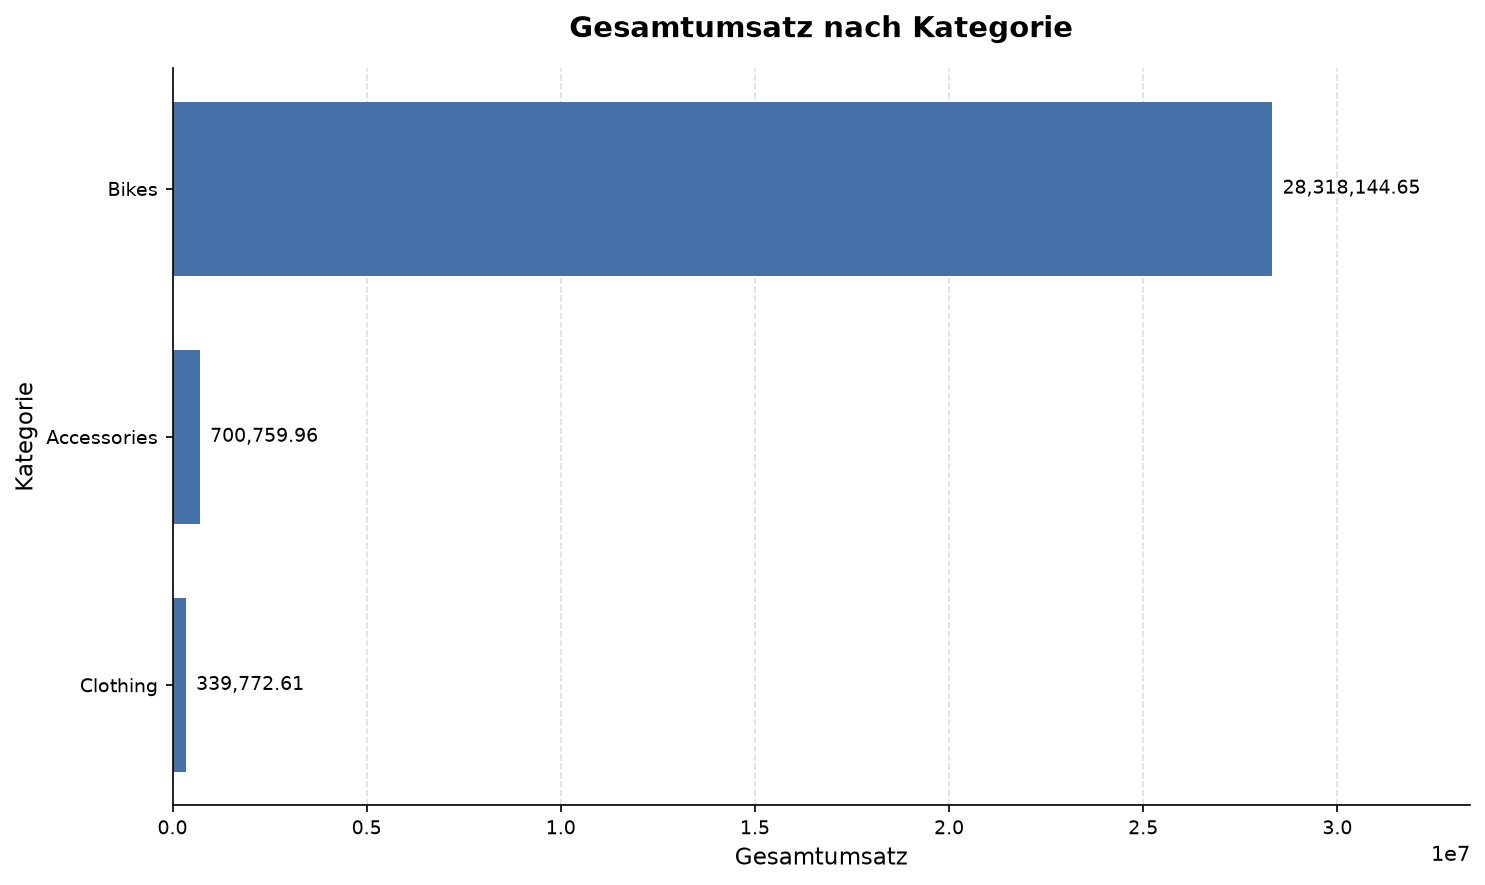

In [93]:
ScientificBarChart(
    sum_sales_amount_category,
    category_col="Category",
    value_col="SumSalesAmount",
    title="Gesamtumsatz nach Kategorie",
    xlabel="Gesamtumsatz",
    ylabel="Kategorie",
).plot()

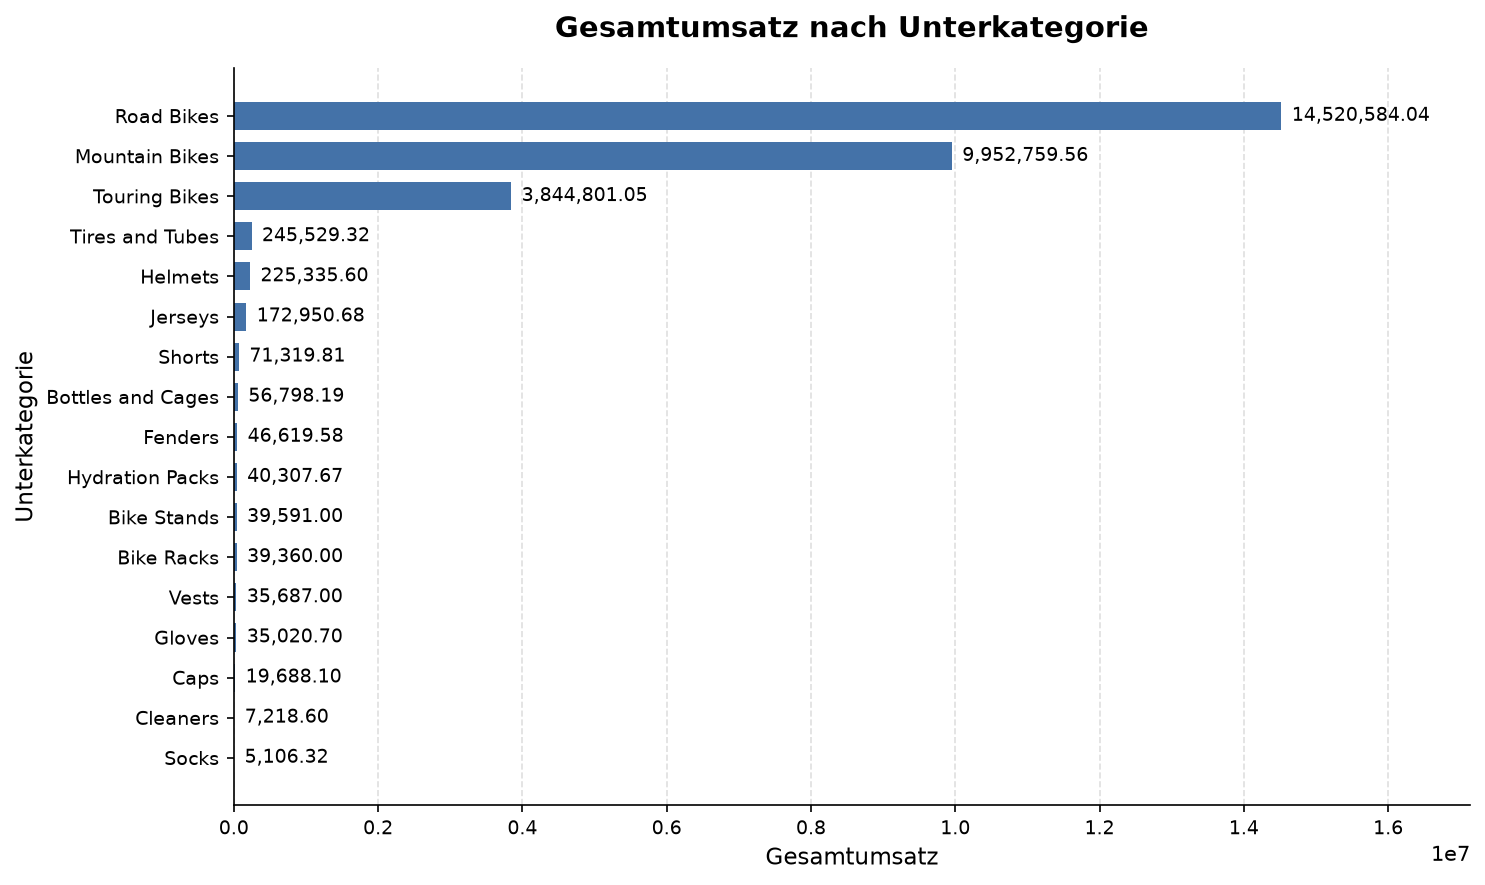

In [94]:
ScientificBarChart(
    sum_sales_amount_subcategory,
    category_col="Subcategory",
    value_col="SumSalesAmount",
    title="Gesamtumsatz nach Unterkategorie",
    xlabel="Gesamtumsatz",
    ylabel="Unterkategorie",
).plot()

In [ ]:
ScientificBarChart(
    sum_sales_amount,
    category_col="Subcategory",
    value_col="SumSalesAmount",
    title="Gesamtumsatz nach Subkategorie",
    xlabel="Gesamtumsatz",
    ylabel="Subkategorie",
).plot()

KeyError: 'Revenue'